In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df['Mujer'] = (df['Sex'] == 'female').astype(int)  # 1 = mujer, 0 = hombre
df['Age'] = df['Age'].fillna(df['Age'].median())  # rellenar edades vacías

variables = ['Pclass', 'Mujer', 'Age', 'Fare']
df[variables].describe()

,Pclass,Mujer,Age,Fare
count,891.000000,891.000000,891.000000,891.000000
mean,2.308642,0.352413,29.361582,32.204208
std,0.836071,0.477990,13.019697,49.693429
min,1.000000,0.000000,0.420000,0.000000
25%,2.000000,0.000000,22.000000,7.910400
50%,3.000000,0.000000,28.000000,14.454200
75%,3.000000,1.000000,35.000000,31.000000
max,3.000000,1.000000,80.000000,512.329200


In [4]:
datos = df[variables]
X = ((datos - datos.mean()) / datos.std()).values  # .values lo convierte en matriz de numpy
print(X.shape)  # (pasajeros, variables)

(891, 4)


In [5]:
def mi_kmeans(X, k, semilla=0, max_vueltas=50):
    np.random.seed(semilla)

    # 1. centroides iniciales: k pasajeros al azar
    posiciones = np.random.choice(len(X), k, replace=False)
    centroides = X[posiciones]

    for vuelta in range(max_vueltas):
        # 2. distancia de cada pasajero a cada centroide
        distancias = np.zeros((len(X), k))
        for j in range(k):
            distancias[:, j] = np.sqrt(((X - centroides[j]) ** 2).sum(axis=1))

        # 3. asignar cada pasajero al centroide más cercano
        grupos = distancias.argmin(axis=1)

        # 4. nuevo centroide = promedio de los pasajeros de cada grupo
        nuevos = np.array([X[grupos == j].mean(axis=0) for j in range(k)])

        # 5. si nada cambió, terminamos
        if np.allclose(nuevos, centroides):
            break
        centroides = nuevos

    return grupos, centroides

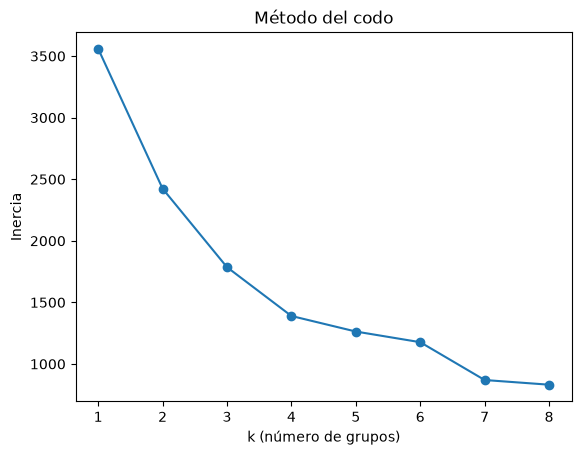

In [6]:
def inercia(X, grupos, centroides):
    total = 0
    for j in range(len(centroides)):
        total += ((X[grupos == j] - centroides[j]) ** 2).sum()
    return total


valores_k = range(1, 9)
inercias = []
for k in valores_k:
    grupos, centroides = mi_kmeans(X, k)
    inercias.append(inercia(X, grupos, centroides))

plt.plot(valores_k, inercias, 'o-')
plt.xlabel('k (número de grupos)')
plt.ylabel('Inercia')
plt.title('Método del codo')
plt.show()

In [7]:
K = 3
grupos, centroides = mi_kmeans(X, K)

df['grupo'] = grupos
df['grupo'].value_counts().sort_index()

grupo
0    222
1    447
2    222
Name: count, dtype: int64

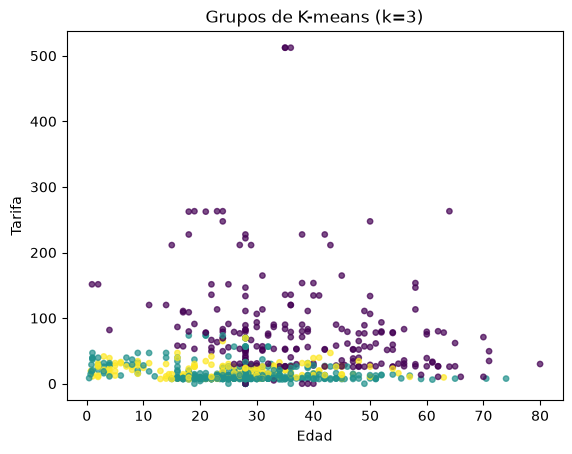

In [8]:
plt.scatter(df['Age'], df['Fare'], c=df['grupo'], s=15, alpha=0.7)
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.title(f'Grupos de K-means (k={K})')
plt.show()

## LIBRERIA PRECARGADA

In [9]:
from sklearn.cluster import KMeans

modelo = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)

print('Inercia de mi K-means :', round(inercia(X, grupos, centroides), 2))
print('Inercia de scikit-learn:', round(modelo.inertia_, 2))

Inercia de mi K-means : 1785.83
Inercia de scikit-learn: 1785.83


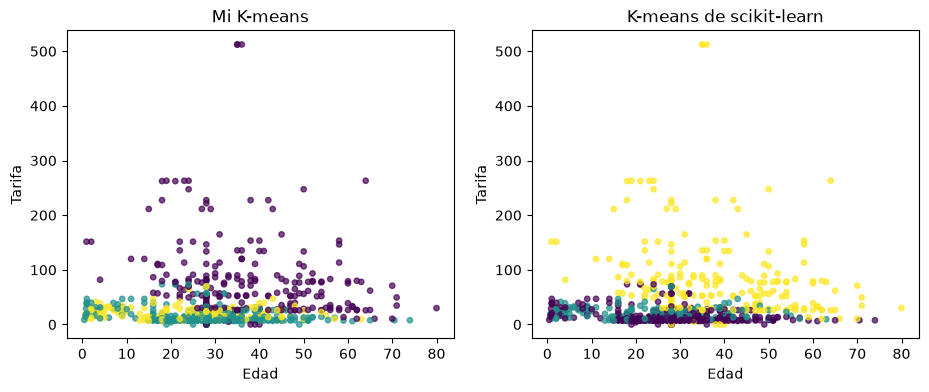

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

# izquierda: nuestro K-means
ejes[0].scatter(df['Age'], df['Fare'], c=grupos, s=15, alpha=0.7)
ejes[0].set_title('Mi K-means')
ejes[0].set_xlabel('Edad')
ejes[0].set_ylabel('Tarifa')

# derecha: K-means de scikit-learn
ejes[1].scatter(df['Age'], df['Fare'], c=modelo.labels_, s=15, alpha=0.7)
ejes[1].set_title('K-means de scikit-learn')
ejes[1].set_xlabel('Edad')
ejes[1].set_ylabel('Tarifa')

plt.show()